# 03 — Survey-weighted cardiovascular statistical analysis

**NHANES 2017–2018 | Portfolio project**

This notebook follows `01_data_preparation.ipynb` and `02_exploratory_analysis.ipynb`. It reads their shared file `data/processed/cardiovascular_data.csv`, **without depending on the previous notebooks' memory**.

### Research objectives
1. Estimate weighted mean systolic and diastolic BP and prevalence of high **measured** BP among US civilian noninstitutionalized adults aged 20+ (2017–2018).
2. Examine how systolic BP differs across age and sex groups.
3. Explore whether BMI is associated with systolic BP after accounting for age and sex.

### Statistical safeguards
- Use **MEC examination weight**, **masked strata**, and **masked PSU** for survey estimation.
- For subgroups, retain the full survey sample for domain variance estimation (do **not** drop all out-of-domain participants before forming design variance).
- Taylor-linearized confidence intervals are calculated at the stratum/PSU level with an approximate t distribution and design degrees of freedom.
- Regression below is a **survey-weighted exploratory approximation**, with stratified PSU-level sandwich variance. Validate against a dedicated survey package (e.g., R `survey` or Stata `svy`) before presenting publishable inferential results.
- Neither elevated BP at one examination nor the questionnaire alone establishes a clinical diagnosis. Observational associations are not causal.

**Important:** This notebook includes no fabricated clinical results; all values are computed from the locally processed CSV.

## 1. Load the file produced by notebook 01

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t

BASE = Path.cwd().resolve()
if BASE.name.lower() == 'notebooks':
    BASE = BASE.parent
DATA_FILE = BASE/'data'/'processed'/'cardiovascular_data.csv'
OUT = BASE/'data'/'processed'
FIG = BASE/'reports'/'figures'
FIG.mkdir(parents=True,exist_ok=True)
if not DATA_FILE.exists():
    raise FileNotFoundError(f'Run notebook 01 first. Expected: {DATA_FILE}')
df = pd.read_csv(DATA_FILE)
required = ['SEQN','RIDAGEYR','sex','age_group','sbp_mean','dbp_mean','bmi',
            'high_measured_bp','mec_weight','SDMVSTRA','SDMVPSU']
missing = set(required)-set(df.columns)
if missing: raise ValueError(f'Missing columns: {sorted(missing)}')
assert df.SEQN.is_unique
print('Adults loaded:',len(df))
print('Survey strata:',df.SDMVSTRA.nunique(),'PSU combinations:',df[['SDMVSTRA','SDMVPSU']].drop_duplicates().shape[0])
print('Missing SBP:',df.sbp_mean.isna().sum())

Adults loaded: 5569
Survey strata: 15 PSU combinations: 30
Missing SBP: 570


## 2. Survey estimation utilities

The ratio estimate is `sum(weight * domain * observed * value) / sum(weight * domain * observed)`.
Its linearized contribution for each participant is `weight * domain * observed * (value - estimate) / sum(weights in domain with observed value)`. PSU totals are centered **within stratum**. For two PSUs per stratum, the unbiased-within-stratum total variance contribution uses `m/(m-1) * sum((PSU-total − stratum-mean)^2)`.

This is a compact educational implementation for NHANES-style masked strata/PSU estimation. It does not implement every possible survey feature (e.g., finite population corrections, sophisticated lonely PSU adjustments or calibrated subsample analysis).

In [2]:
def design_variance(linearized, strata, psu):
    temp = pd.DataFrame({'lin':np.asarray(linearized,dtype=float),
                         'strata':np.asarray(strata), 'psu':np.asarray(psu)})
    if temp[['strata','psu']].isna().any().any():
        raise ValueError('Missing design IDs')
    groups = temp.groupby(['strata','psu'],observed=True)['lin'].sum().reset_index()
    variance = 0.0
    for _, block in groups.groupby('strata',observed=True):
        m = len(block)
        if m<2: raise ValueError('Single-PSU stratum: cannot calculate design variance safely')
        variance += m/(m-1) * ((block['lin']-block['lin'].mean())**2).sum()
    n_psu = len(groups)
    n_strata = groups['strata'].nunique()
    return float(variance), int(n_psu-n_strata)

def survey_mean(frame, variable, domain=None):
    y = pd.to_numeric(frame[variable],errors='coerce')
    w = pd.to_numeric(frame.mec_weight,errors='coerce')
    domain = pd.Series(True,index=frame.index) if domain is None else domain.fillna(False).astype(bool)
    eligible = domain & y.notna() & w.notna() & (w>0)
    numerator = (w.where(eligible,0)*y.fillna(0)).sum()
    denominator = w.where(eligible,0).sum()
    if denominator<=0: raise ValueError(f'No weighted observations for {variable}')
    mean = numerator/denominator
    lin = (w.where(eligible,0)*(y.fillna(0)-mean)/denominator).to_numpy()
    variance, dof = design_variance(lin,frame.SDMVSTRA,frame.SDMVPSU)
    se = np.sqrt(max(variance,0))
    crit = student_t.ppf(0.975,df=dof)
    return {'n':int(eligible.sum()),'estimate':float(mean),'se':float(se),
            'ci_low':float(mean-crit*se),'ci_high':float(mean+crit*se),
            'design_df':dof}

sample = df.loc[df.mec_weight.notna() & (df.mec_weight>0)
                & df.SDMVSTRA.notna() & df.SDMVPSU.notna()].copy()
print('Survey-eligible adults:',len(sample))
print('Design degrees of freedom:', sample[['SDMVSTRA','SDMVPSU']].drop_duplicates().shape[0]-sample.SDMVSTRA.nunique())

Survey-eligible adults: 5569
Design degrees of freedom: 15


## 3. Population-weighted overall results and uncertainty

In [3]:
results = []
for variable,label,unit in [('sbp_mean','Systolic BP','mmHg'),
                            ('dbp_mean','Diastolic BP','mmHg'),
                            ('high_measured_bp','High measured BP','proportion')]:
    z=survey_mean(sample,variable)
    results.append({'metric':label,'unit':unit,**z})
overall=pd.DataFrame(results)
display(overall.round(3))
overall.to_csv(OUT/'survey_overall_estimates.csv',index=False)
print('Note: high measured BP uses the project’s >=130 SBP OR >=80 DBP definition,')
print('and requires both average measurements; it does not equal diagnosed hypertension.')

,metric,unit,n,estimate,se,ci_low,ci_high,design_df
0,Systolic BP,mmHg,4999,123.818,0.475,122.805,124.831,15
1,Diastolic BP,mmHg,4984,72.784,0.553,71.605,73.964,15
2,High measured BP,proportion,4984,0.397,0.012,0.372,0.422,15


Note: high measured BP uses the project’s >=130 SBP OR >=80 DBP definition,
and requires both average measurements; it does not equal diagnosed hypertension.


## 4. Group comparisons (domain estimation)

Each domain is indicated within the complete adult survey frame rather than deleting everybody outside that subgroup prior to variance estimation.

In [4]:
rows=[]
for sex in ['Female','Male']:
    for age in ['20–39','40–59','60–79','80+']:
        domain = sample.sex.eq(sex)&sample.age_group.eq(age)
        for variable in ['sbp_mean','high_measured_bp']:
            try:
                x=survey_mean(sample,variable,domain=domain)
                rows.append({'sex':sex,'age_group':age,'metric':variable,**x})
            except ValueError:
                rows.append({'sex':sex,'age_group':age,'metric':variable,
                             'n':0,'estimate':np.nan,'se':np.nan,'ci_low':np.nan,
                             'ci_high':np.nan,'design_df':np.nan})
group_results=pd.DataFrame(rows)
display(group_results.round(3))
group_results.to_csv(OUT/'survey_group_estimates.csv',index=False)

,sex,age_group,metric,n,estimate,se,ci_low,ci_high,design_df
0,Female,20–39,sbp_mean,792,110.991,0.562,109.794,112.189,15
1,Female,20–39,high_measured_bp,791,0.124,0.017,0.088,0.161,15
2,Female,40–59,sbp_mean,836,123.328,0.820,121.581,125.075,15
3,Female,40–59,high_measured_bp,835,0.402,0.021,0.358,0.446,15
4,Female,60–79,sbp_mean,767,132.783,1.087,130.465,135.100,15
5,Female,60–79,high_measured_bp,762,0.491,0.028,0.432,0.550,15
6,Female,80+,sbp_mean,176,147.417,1.883,143.404,151.429,15
7,Female,80+,high_measured_bp,172,0.808,0.036,0.731,0.885,15
8,Male,20–39,sbp_mean,704,120.046,0.703,118.549,121.544,15
9,Male,20–39,high_measured_bp,703,0.324,0.021,0.279,0.369,15


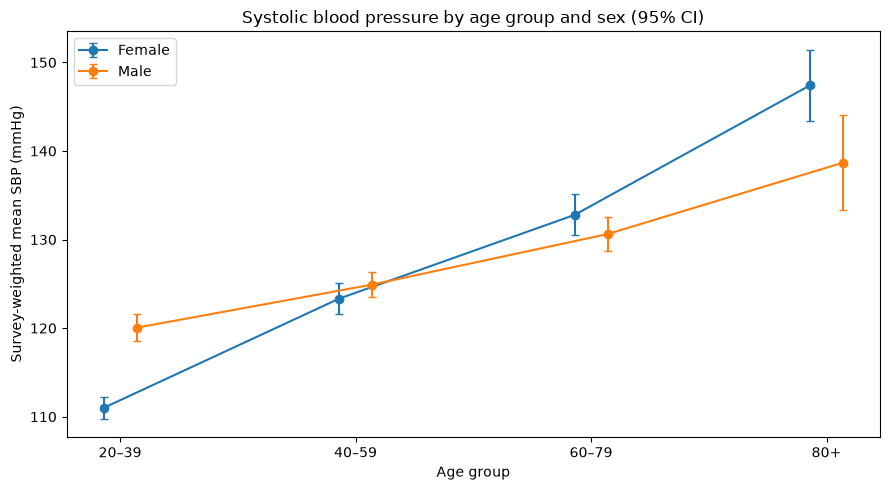

In [5]:
show=group_results[group_results.metric=='sbp_mean'].copy()
fig,ax=plt.subplots(figsize=(9,5))
for sex,part in show.groupby('sex'):
    part=part.set_index('age_group').reindex(['20–39','40–59','60–79','80+']).reset_index()
    x=np.arange(len(part)) + (-0.07 if sex=='Female' else 0.07)
    ax.errorbar(x,part.estimate,yerr=[part.estimate-part.ci_low,part.ci_high-part.estimate],
                fmt='o-',capsize=3,label=sex)
ax.set_xticks(np.arange(4),['20–39','40–59','60–79','80+'])
ax.set(xlabel='Age group',ylabel='Survey-weighted mean SBP (mmHg)',
       title='Systolic blood pressure by age group and sex (95% CI)')
ax.legend();fig.tight_layout()
fig.savefig(FIG/'survey_sbp_by_age_and_sex.png',dpi=160)
plt.show()

## 5. Exploratory adjusted association: BMI and systolic blood pressure

A weighted regression estimates the change in SBP associated with a one-unit higher BMI, **holding age and reported sex constant in the linear model**. Standard errors are approximated using PSU-level residual score totals centered inside strata. The design uses the complete adult survey frame with zero score contributions from respondents excluded because of missing regression values; verify estimates using a specialist survey-analysis package before external publication.

Regression is associational and may be sensitive to omitted covariates, measurement effects, model form and missingness.

In [6]:
import statsmodels.api as sm
model_ok = sample[['sbp_mean','bmi','RIDAGEYR','sex','mec_weight']].notna().all(axis=1)
model_ok &= sample.sex.isin(['Male','Female'])
sub=sample.loc[model_ok].copy()
X=pd.DataFrame({'intercept':1.0,'bmi':sub.bmi.astype(float),
                'age_years':sub.RIDAGEYR.astype(float),
                'male':sub.sex.eq('Male').astype(float)}, index=sub.index)
y=sub.sbp_mean.astype(float).to_numpy()
w=sub.mec_weight.astype(float).to_numpy()
Xmat=X.to_numpy()
# Numerical weighted least squares, with exact coefficient estimates.
xtwx=Xmat.T@(w[:,None]*Xmat)
beta=np.linalg.solve(xtwx,Xmat.T@(w*y))
resid=y-Xmat@beta
# Covariance of coefficients using Taylor-linearized stratified PSU score totals.
# Use the entire design frame for domain treatment of missing covariates.
scores=pd.DataFrame(0.0,index=sample.index,columns=X.columns)
scores.loc[sub.index,:] = (w*resid)[:,None]*Xmat
bread_inv=np.linalg.inv(xtwx)
var_beta=np.zeros((len(beta),len(beta)))
psu_scores=scores.copy()
psu_scores['strata']=sample.SDMVSTRA.to_numpy()
psu_scores['psu']=sample.SDMVPSU.to_numpy()
psu_totals=psu_scores.groupby(['strata','psu'],observed=True)[list(X.columns)].sum().reset_index()
for _,block in psu_totals.groupby('strata',observed=True):
    m=len(block)
    if m<2: raise ValueError('Single-PSU stratum in model')
    z=block[list(X.columns)].to_numpy()
    centered=z-z.mean(axis=0)
    var_beta+=m/(m-1)*(centered.T@centered)
var_beta=bread_inv@var_beta@bread_inv
se=np.sqrt(np.clip(np.diag(var_beta),0,np.inf))
df_design=int(len(psu_totals)-psu_totals.strata.nunique())
crit=student_t.ppf(0.975,df=df_design)
regression=pd.DataFrame({'predictor':X.columns,'coefficient':beta,'std_error':se,
                         'ci_low':beta-crit*se,'ci_high':beta+crit*se})
print('Regression sample:',len(sub),'of',len(sample),'survey-eligible adults')
print('Approximate design degrees of freedom:',df_design)
display(regression.round(3))
regression.to_csv(OUT/'survey_regression_approximation.csv',index=False)

Regression sample: 4935 of 5569 survey-eligible adults
Approximate design degrees of freedom: 15


,predictor,coefficient,std_error,ci_low,ci_high
0,intercept,87.602,1.240,84.959,90.245
1,bmi,0.418,0.045,0.323,0.514
2,age_years,0.458,0.017,0.421,0.494
3,male,3.100,0.667,1.679,4.521


## 6. Interpretation and sensitivity checks

The primary model above uses a linear age term and a single male-female difference. The next section investigates whether the association between age category and SBP differs by sex.

These are observational, cross-sectional associations. CIs and statistical comparisons in this notebook use a transparent custom Taylor-linearization approximation and should be validated using dedicated complex-survey software before being reported as definitive findings. The age variable is top-coded at 80 in public NHANES files; we therefore use age categories rather than interpret age slopes above 80.

## 7. Does the age-group pattern differ by sex?

**Pre-specified extended analysis** based on notebook 02: compare an additive survey-weighted model (`BMI + age group + sex`) with an interaction model (`BMI + age group * sex`). Both models use **the exact same complete-case cohort**, making their coefficients directly comparable.

- Outcome: mean systolic blood pressure (mmHg).
- Reference: women aged 20–39, with BMI adjusted in the model.
- Interaction test: a joint Wald F test of the three age-group × male terms, using the approximate linearized design covariance; this is **not a causal test**.
- This is a model-based comparison, and because BMI may differ by age or sex, adjusted predictions need not match unadjusted group means in section 4.

In [7]:
from scipy.stats import f as f_dist

AGE_GROUPS = ['20–39','40–59','60–79','80+']
needed = ['sbp_mean','bmi','age_group','sex','mec_weight']
valid = sample[needed].notna().all(axis=1)
valid &= sample.age_group.isin(AGE_GROUPS) & sample.sex.isin(['Male','Female'])
model_data = sample.loc[valid].copy()

male = model_data.sex.eq('Male').astype(float)
X_add = pd.DataFrame(index=model_data.index)
X_add['intercept'] = 1.0
X_add['bmi'] = model_data.bmi.astype(float)
for age in AGE_GROUPS[1:]:
    X_add['age_' + age] = model_data.age_group.eq(age).astype(float)
X_add['male'] = male

X_inter = X_add.copy()
for age in AGE_GROUPS[1:]:
    X_inter['male_x_age_' + age] = male * model_data.age_group.eq(age).astype(float)

print('Same participants in both models:', len(model_data))
print('Age/sex group sizes:')
display(model_data.groupby(['age_group','sex'], observed=True).size().rename('n').unstack(fill_value=0))

Same participants in both models: 4935
Age/sex group sizes:


sex,Female,Male
age_group,,
20–39,791,698
40–59,825,739
60–79,758,796
80+,167,161


In [8]:
def fit_survey_wls(model_frame, predictors, outcome='sbp_mean'):
    """Weighted coefficient estimates and custom Taylor-linearized stratified-PSU covariance.

    This is an educational implementation; check results against a specialized survey package.
    """
    y = model_frame[outcome].astype(float).to_numpy()
    w = model_frame['mec_weight'].astype(float).to_numpy()
    matrix = predictors.astype(float).to_numpy()
    hessian = matrix.T @ (w[:, None] * matrix)
    if np.linalg.matrix_rank(hessian) != len(predictors.columns):
        raise ValueError('Rank-deficient model: check subgroup sample sizes')
    beta = np.linalg.solve(hessian, matrix.T @ (w * y))
    residual = y - matrix @ beta
    # Preserve all sampled survey clusters, with zero score contributions outside the model domain.
    scores = pd.DataFrame(0.0, index=sample.index, columns=predictors.columns)
    scores.loc[model_frame.index, :] = (w * residual)[:, None] * matrix
    scores['strata'] = sample.SDMVSTRA.to_numpy()
    scores['psu'] = sample.SDMVPSU.to_numpy()
    aggregated = scores.groupby(['strata','psu'], observed=True)[list(predictors.columns)].sum().reset_index()
    meat = np.zeros((matrix.shape[1], matrix.shape[1]))
    for _, group in aggregated.groupby('strata', observed=True):
        n_units = len(group)
        if n_units < 2:
            raise ValueError('Single-PSU stratum')
        z = group[list(predictors.columns)].to_numpy()
        centered = z - z.mean(axis=0)
        meat += n_units / (n_units - 1) * (centered.T @ centered)
    hessian_inv = np.linalg.inv(hessian)
    covariance = hessian_inv @ meat @ hessian_inv
    covariance = (covariance + covariance.T)/2
    df_design = len(aggregated) - aggregated.strata.nunique()
    critical = student_t.ppf(.975, df_design)
    se = np.sqrt(np.clip(np.diag(covariance), 0, np.inf))
    coefficients = pd.DataFrame({'predictor':list(predictors.columns),'coefficient':beta,
                                 'std_error':se,'ci_low':beta-critical*se,
                                 'ci_high':beta+critical*se})
    return {'coefficients':coefficients,'beta':beta,'covariance':covariance,
            'design_df':df_design,'predictors':list(predictors.columns)}

additive = fit_survey_wls(model_data, X_add)
interaction = fit_survey_wls(model_data, X_inter)
print('Additive model (same participants as interaction model):')
display(additive['coefficients'].round(3))
print('Interaction model:')
display(interaction['coefficients'].round(3))
additive['coefficients'].to_csv(OUT/'survey_additive_agegroup_model.csv', index=False)
interaction['coefficients'].to_csv(OUT/'survey_age_sex_interaction_model.csv', index=False)

Additive model (same participants as interaction model):


,predictor,coefficient,std_error,ci_low,ci_high
0,intercept,101.133,1.227,98.518,103.748
1,bmi,0.438,0.042,0.350,0.527
2,age_40–59,8.024,0.723,6.482,9.566
3,age_60–79,15.989,0.814,14.254,17.725
4,age_80+,28.773,1.636,25.285,32.261
5,male,3.050,0.646,1.673,4.427


Interaction model:


,predictor,coefficient,std_error,ci_low,ci_high
0,intercept,97.879,1.197,95.326,100.431
1,bmi,0.442,0.043,0.350,0.534
2,age_40–59,11.852,0.904,9.925,13.779
3,age_60–79,21.584,1.261,18.897,24.271
4,age_80+,36.953,2.109,32.458,41.448
5,male,9.347,0.747,7.754,10.939
6,male_x_age_40–59,-7.678,1.049,-9.913,-5.443
7,male_x_age_60–79,-11.478,1.370,-14.398,-8.557
8,male_x_age_80+,-18.767,3.736,-26.730,-10.805


## 8. Joint interaction test

A **joint test** is preferable to interpreting individual interaction terms one at a time. The null hypothesis is that all three age-group × sex interaction coefficients equal zero. The Wald test below is an approximation based on the notebook's custom survey covariance; confirm with `survey::svyglm` and `survey::regTermTest` (R) for a publication-quality analysis.

In [9]:
interaction_names = [c for c in X_inter.columns if c.startswith('male_x_age_')]
idx = [interaction['predictors'].index(name) for name in interaction_names]
beta_int = interaction['beta'][idx]
cov_int = interaction['covariance'][np.ix_(idx, idx)]
q = len(idx)
wald_f = float(beta_int @ np.linalg.solve(cov_int, beta_int) / q)
p_interaction = float(f_dist.sf(wald_f, q, interaction['design_df']))
interaction_test = pd.DataFrame([{'test':'Joint age-group x sex interaction',
                                  'F_approx':wald_f,'df_num':q,
                                  'df_den':interaction['design_df'],
                                  'p_approx':p_interaction,'n':len(model_data)}])
display(interaction_test)
interaction_test.to_csv(OUT/'survey_age_sex_interaction_test_APPROX.csv', index=False)
print('Interpret p values cautiously until independently validated.')

,test,F_approx,df_num,df_den,p_approx,n
0,Joint age-group x sex interaction,31.84021,3,15,9.504491e-07,4935


Interpret p values cautiously until independently validated.


## 9. Adjusted group predictions at a common BMI

Compute **model-based** mean SBP in each group, setting BMI to the weighted mean BMI of this complete-case analytic sample. Holding BMI constant isolates the model's conditional age-group and sex comparisons, but it does **not** make them causal effects.

Confidence intervals are computed from the same approximate survey covariance used by the model. These do not replace the direct domain estimates in section 4.

,age_group,sex,adjusted_sbp,ci_low,ci_high,bmi_reference
0,20–39,Female,111.06,109.99,112.12,29.83
1,20–39,Male,120.40,119.14,121.66,29.83
2,40–59,Female,122.91,121.14,124.68,29.83
3,40–59,Male,124.58,123.06,126.10,29.83
4,60–79,Female,132.64,130.41,134.87,29.83
5,60–79,Male,130.51,128.62,132.39,29.83
6,80+,Female,148.01,143.80,152.22,29.83
7,80+,Male,138.59,132.50,144.67,29.83


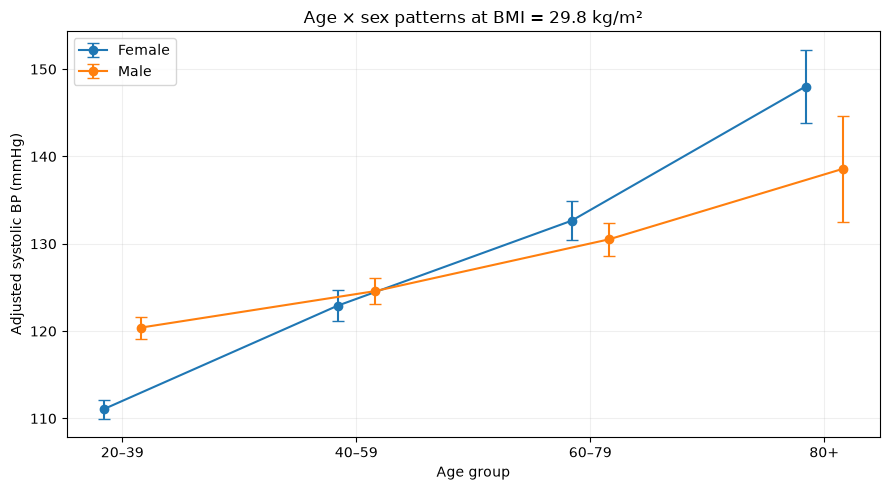

In [10]:
reference_bmi = np.average(model_data.bmi, weights=model_data.mec_weight)
rows = []
for age in AGE_GROUPS:
    for sex in ['Female','Male']:
        male_value = float(sex == 'Male')
        x_row = {name:0.0 for name in X_inter.columns}
        x_row.update({'intercept':1.0, 'bmi':float(reference_bmi), 'male':male_value})
        for group in AGE_GROUPS[1:]:
            x_row['age_'+group] = float(age==group)
            x_row['male_x_age_'+group] = male_value * float(age==group)
        v = np.array([x_row[c] for c in X_inter.columns])
        estimate = float(v @ interaction['beta'])
        se = float(np.sqrt(max(0, v @ interaction['covariance'] @ v)))
        critical = student_t.ppf(.975,interaction['design_df'])
        rows.append({'age_group':age,'sex':sex,'adjusted_sbp':estimate,
                     'ci_low':estimate-critical*se,'ci_high':estimate+critical*se,
                     'bmi_reference':reference_bmi})
predictions = pd.DataFrame(rows)
display(predictions.round(2))
predictions.to_csv(OUT/'survey_age_sex_adjusted_predictions_APPROX.csv',index=False)
fig, ax = plt.subplots(figsize=(9,5))
x = np.arange(len(AGE_GROUPS))
for sex, shift in [('Female',-0.08),('Male',0.08)]:
    part = predictions.set_index(['age_group','sex']).loc[[(a,sex) for a in AGE_GROUPS]]
    means = part.adjusted_sbp.to_numpy()
    err = np.vstack([means-part.ci_low.to_numpy(),part.ci_high.to_numpy()-means])
    ax.errorbar(x+shift, means,yerr=err, marker='o', capsize=4,label=sex)
ax.set_xticks(x,AGE_GROUPS)
ax.set(xlabel='Age group',ylabel='Adjusted systolic BP (mmHg)',
       title=f'Age × sex patterns at BMI = {reference_bmi:.1f} kg/m²')
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(FIG/'survey_adjusted_sbp_age_sex_interaction_APPROX.png',dpi=160)
plt.show()

## 10. Interpret before publishing

Answer these in English in your final report:

1. Do the **direct survey-weighted age–sex group estimates** in section 4 resemble the model's adjusted predictions?
2. Is there evidence of an **age-group × sex interaction**? Record the approximate joint test and its validation status.
3. What is the **BMI coefficient** in the extended model? Does it materially differ from the earlier model?
4. How might age top-coding, the cross-sectional design, missing BP readings, medications, and the prespecified outlier thresholds affect interpretation?

**Quality gate:** The linearized variances in this notebook are custom code. Do **not** describe hypothesis tests or CIs as independently validated until the estimates have been checked in a package that natively supports NHANES complex survey design (for example, R `survey`).

**Next step:** review the resulting tables and graphs together, then validate the survey design calculations and create a curated Power BI dataset.